# 1. Librarys

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import statsmodels.formula.api as smf
from itertools import product
from math import gcd
from functools import reduce

# 2. Database

In [2]:
full_df = pd.concat(
    [pd.read_csv(r"Bases\range(2005, 2011)_final_data.csv"),
    pd.read_csv(r"Bases\range(2010, 2016)_final_data.csv"),
    pd.read_csv(r"Bases\range(2015, 2021)_final_data.csv"),
    pd.read_csv(r"Bases\range(2020, 2025)_final_data.csv"),
    pd.read_csv(r"Bases\range(2024, 2026)_final_data.csv")
    ]
    ).reset_index(drop=True)

full_df.sample(5, random_state=42)

,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02,precip_10_ly,precip_11_ly,precip_12_ly,precip_01,precip_02,ndvi_10_ly,ndvi_11_ly,ndvi_12_ly,ndvi_01,ndvi_02,ndvi_03,PROD_SOJA
10650,Cabeceiras,GO,2016,37.538240,35.845610,34.080963,32.089996,33.382477,31.700533,149.86075,120.00781,323.60596,58.334606,0.327105,0.435255,0.500005,0.701300,0.726174,0.600274,2900.0
2041,Ipuaçu,SC,2007,32.698395,32.074370,33.544098,30.812408,30.685944,144.675230,174.53810,210.34612,180.87419,166.961780,0.633320,0.638960,0.729940,0.820250,0.835080,0.754980,2500.0
8668,Reserva do Iguaçu,PR,2014,28.527008,30.050201,29.452790,30.604645,31.803620,135.243450,108.04855,188.46315,203.37184,120.803270,0.715817,0.721980,0.761687,0.820937,0.828090,0.777027,3380.0
1114,Colorado,RS,2010,33.974030,35.486970,32.670074,32.546783,35.292145,134.427690,369.50186,169.60869,215.09729,176.798510,0.587950,0.427270,0.458850,0.823040,0.845480,0.738500,3300.0
13902,Santa Cruz do Rio Pardo,SP,2018,36.388092,33.132477,34.430573,33.635162,34.088776,220.162310,125.28750,193.55215,261.44702,156.910480,0.481145,0.574143,0.685530,0.786375,0.698050,0.649730,3600.0


In [3]:
df_filt = full_df[full_df['YEAR'] < 2025].copy()

In [4]:
df_filt['YEAR'].unique()

array([2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016,
       2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024])

In [5]:
print(df_filt.sample(5, random_state=42).to_latex())

\begin{tabular}{lllrrrrrrrrrrrrrrrrrr}
\toprule
 & NM_MUN & SIGLA_UF & YEAR & t2m_10_ly & t2m_11_ly & t2m_12_ly & t2m_01 & t2m_02 & precip_10_ly & precip_11_ly & precip_12_ly & precip_01 & precip_02 & ndvi_10_ly & ndvi_11_ly & ndvi_12_ly & ndvi_01 & ndvi_02 & ndvi_03 & PROD_SOJA \\
\midrule
7592 & Mangueirinha & PR & 2013 & 32.953033 & 30.800446 & 30.781890 & 30.116852 & 30.783356 & 266.050480 & 49.188526 & 245.068280 & 179.173580 & 245.929920 & 0.593755 & 0.616813 & 0.749411 & 0.833429 & 0.774705 & 0.692847 & 3362.000000 \\
12051 & Ipuã & SP & 2017 & 37.539703 & 33.951813 & 34.817535 & 34.759186 & 34.690340 & 138.712800 & 209.387800 & 220.045850 & 245.662670 & 151.941270 & 0.395567 & 0.482447 & 0.702640 & 0.773900 & 0.706447 & 0.699827 & 3626.000000 \\
17353 & Nova Fátima & PR & 2022 & 30.573883 & 35.086823 & 34.321930 & 34.101960 & 34.102448 & 188.782270 & 65.304535 & 82.965580 & 82.867100 & 122.458060 & 0.507100 & 0.549236 & 0.696155 & 0.817182 & 0.850327 & 0.715691 & 3540.000000 \\

# 3. Relevant statistics

## i. Variables behavior

In [6]:
desc_table = df_filt.drop(columns=['YEAR']).describe().T[['count', 'min', '50%', 'max', 'mean', 'std']]
desc_table.index = ['Temperatura máxima outubro', 'Temperatura máxima novembro', 'Temperatura máxima dezembro', 'Temperatura máxima janeiro', 'Temperatura máxima fevereiro',
                    'Precipitação total outubro', 'Precipitação total novembro', 'Precipitação total dezembro', 'Precipitação total janeiro', 'Precipitação total fevereiro',
                    'NDVI outubro', 'NDVI novembro', 'NDVI dezembro', 'NDVI janeiro', 'NDVI fevereiro', 'NDVI março', 'Produtividade de soja']
desc_table.columns = ['Número de observações', 'Mínimo', 'Mediana', 'Máximo', 'Média', 'Desvio padrão']
desc_table['Número de observações'] = desc_table['Número de observações'].astype(int)
desc_table[desc_table.columns[1:]] = round(desc_table[desc_table.columns[1:]], 2).astype(str)
print(desc_table.to_latex())

\begin{tabular}{lrlllll}
\toprule
 & Número de observações & Mínimo & Mediana & Máximo & Média & Desvio padrão \\
\midrule
Temperatura máxima outubro & 19000 & 24.74 & 34.87 & 43.58 & 34.55 & 3.37 \\
Temperatura máxima novembro & 19000 & 25.42 & 33.48 & 42.1 & 33.48 & 2.45 \\
Temperatura máxima dezembro & 19000 & 27.07 & 33.38 & 41.16 & 33.39 & 1.93 \\
Temperatura máxima janeiro & 19000 & 27.27 & 33.1 & 40.04 & 33.1 & 1.93 \\
Temperatura máxima fevereiro & 19000 & 26.74 & 33.06 & 39.52 & 33.04 & 1.92 \\
Precipitação total outubro & 19000 & 4.56 & 152.37 & 846.4 & 172.85 & 95.59 \\
Precipitação total novembro & 19000 & 4.29 & 147.91 & 737.75 & 161.76 & 80.27 \\
Precipitação total dezembro & 19000 & 7.99 & 200.0 & 577.86 & 204.34 & 90.52 \\
Precipitação total janeiro & 19000 & 3.37 & 215.96 & 656.92 & 226.18 & 84.62 \\
Precipitação total fevereiro & 19000 & 5.67 & 179.09 & 640.49 & 189.98 & 79.07 \\
NDVI outubro & 19000 & 0.26 & 0.55 & 0.85 & 0.55 & 0.12 \\
NDVI novembro & 19000 & 0.28 &

## ii. Correlation

a. With productivity

In [7]:
vars_corr = df_filt.columns[3:]

corr_df_filt = []

for mun, g in df_filt.groupby("SIGLA_UF"):
    corr = g[vars_corr].corrwith(g["PROD_SOJA"])
    corr.name = mun
    corr_df_filt.append(corr)

# dataframe com as correlações por município
corr_df_filt = pd.DataFrame(corr_df_filt)

# agora calcule min, mean e max em cada variável
summary = pd.DataFrame({
    "mean": corr_df_filt.mean(),
    "min": corr_df_filt.min(),
    "median": corr_df_filt.median(),
    "max": corr_df_filt.max()
})

summary = summary.sort_values(by='mean', ascending=False, key=abs)
# pretty_names = [
#     'Temp Out', 'Temp Nov', 'Temp Dez', 'Temp Jan', 'Temp Fev',
#     'Prec Out', 'Prec Nov', 'Prec Dez', 'Prec Jan', 'Prec Fev',
#     'NDVI Out', 'NDVI Nov', 'NDVI Dez', 'NDVI Jan', 'NDVI Fev', 'NDVI Mar'
# ]

# print(summary.sort_values(by='mean', ascending=False, key=abs).to_latex())
summary.index = summary.index.to_series().replace({"PROD_SOJA": "Produtividade ",
                                                   "ndvi": "NDVI ", "precip": "Prec ", "t2m": 'Temp ', 
                                                   '_01': 'Jan', '_02': 'Fev', '_03': 'Mar',
                                                   '_10_ly': 'Out', '_11_ly': 'Nov', '_12_ly': 'Dez'}, regex=True)
summary = summary.round(2).astype(str)
summary.columns = ['Média', 'Mínimo', 'Mediana', 'Máximo']
print(summary.to_latex())

\begin{tabular}{lllll}
\toprule
 & Média & Mínimo & Mediana & Máximo \\
\midrule
Produtividade  & 1.0 & 1.0 & 1.0 & 1.0 \\
NDVI Jan & 0.35 & -0.02 & 0.38 & 0.75 \\
NDVI Fev & 0.22 & -0.22 & 0.25 & 0.65 \\
NDVI Dez & 0.22 & -0.07 & 0.26 & 0.45 \\
Prec Fev & 0.19 & -0.15 & 0.19 & 0.47 \\
Temp Dez & -0.14 & -0.37 & -0.12 & 0.13 \\
Temp Jan & -0.13 & -0.35 & -0.14 & 0.18 \\
Temp Fev & -0.1 & -0.42 & -0.12 & 0.16 \\
Prec Dez & 0.1 & -0.16 & 0.05 & 0.44 \\
Temp Nov & -0.06 & -0.3 & -0.06 & 0.21 \\
NDVI Out & -0.06 & -0.35 & -0.07 & 0.06 \\
NDVI Mar & 0.05 & -0.18 & 0.05 & 0.3 \\
Temp Out & 0.04 & -0.17 & 0.02 & 0.21 \\
NDVI Nov & 0.02 & -0.22 & 0.05 & 0.19 \\
Prec Jan & 0.02 & -0.38 & 0.02 & 0.56 \\
Prec Nov & 0.02 & -0.18 & -0.01 & 0.31 \\
Prec Out & -0.0 & -0.25 & 0.02 & 0.24 \\
\bottomrule
\end{tabular}



### b. Correlation matrix 

* assumir o risco das variaveis correlacionadas | quero verificar como as defasagens explicam a produtividade 
* estudar o comportamento delas (AR)
* rodar modelos alternativos com menos defasagens | quanto altera as conclusoes?

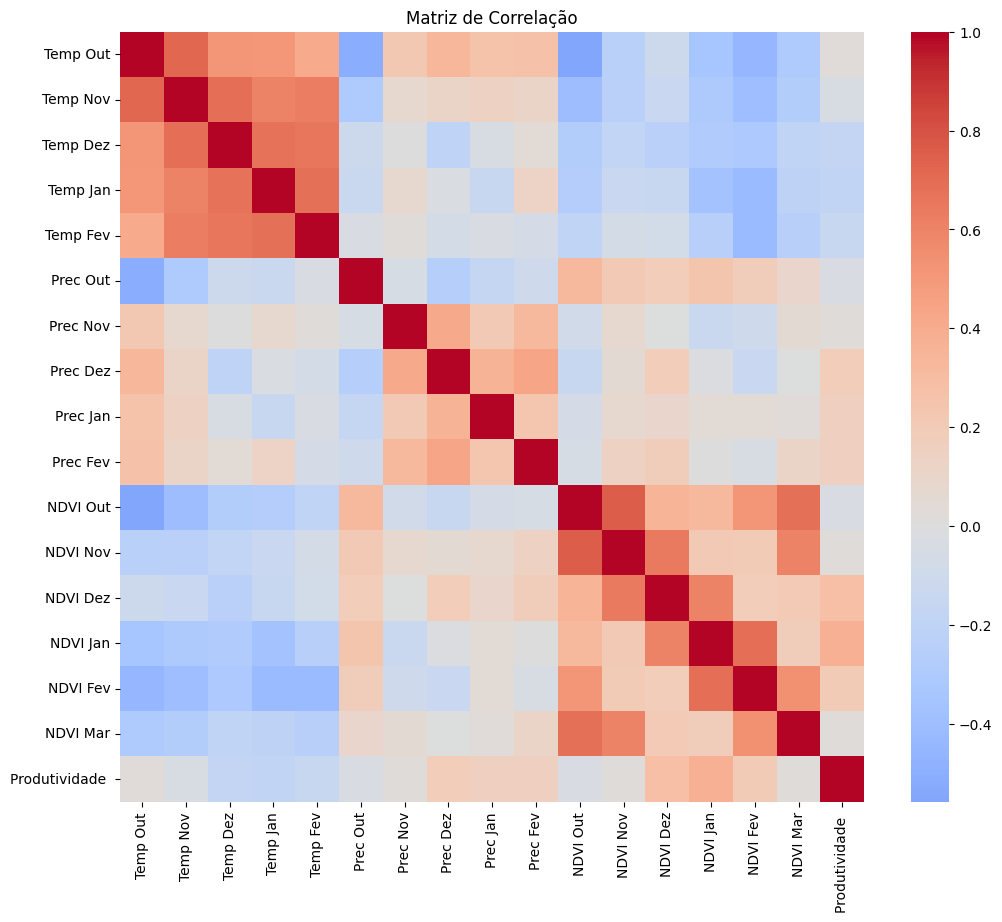

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_filt[df_filt.columns[3:]].corr()
corr.index= corr.index.to_series().replace({"PROD_SOJA": "Produtividade ",
                                                   "ndvi": "NDVI ", "precip": "Prec ", "t2m": 'Temp ', 
                                                   '_01': 'Jan', '_02': 'Fev', '_03': 'Mar',
                                                   '_10_ly': 'Out', '_11_ly': 'Nov', '_12_ly': 'Dez'}, regex=True)

corr.columns= corr.columns.to_series().replace({"PROD_SOJA": "Produtividade ",
                                                   "ndvi": "NDVI ", "precip": "Prec ", "t2m": 'Temp ', 
                                                   '_01': 'Jan', '_02': 'Fev', '_03': 'Mar',
                                                   '_10_ly': 'Out', '_11_ly': 'Nov', '_12_ly': 'Dez'}, regex=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Matriz de Correlação')
plt.show()


In [9]:
corr[corr >= 0.7]

,Temp Out,Temp Nov,Temp Dez,Temp Jan,Temp Fev,Prec Out,Prec Nov,Prec Dez,Prec Jan,Prec Fev,NDVI Out,NDVI Nov,NDVI Dez,NDVI Jan,NDVI Fev,NDVI Mar,Produtividade
Temp Out,1.00000,0.72094,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp Nov,0.72094,1.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp Dez,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp Jan,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp Fev,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prec Out,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prec Nov,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prec Dez,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prec Jan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Prec Fev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 4. Regressions

## i. Variables

In [10]:
temp_vars = ["t2m_10_ly", "t2m_11_ly", "t2m_12_ly", "t2m_01", "t2m_02"]
precip_vars = ["precip_10_ly", "precip_11_ly", "precip_12_ly", "precip_01", "precip_02"]
ndvi_vars = ["ndvi_10_ly", "ndvi_11_ly", "ndvi_12_ly", "ndvi_01", "ndvi_02", "ndvi_03"]

### a. Generic vars

In [11]:
for var in temp_vars + precip_vars:
    full_df[f"{var}_sq"] = full_df[var]**2

full_df["TimeTrend"] = full_df["YEAR"] - full_df["YEAR"].min() - 1

state_dummies = pd.get_dummies(full_df["SIGLA_UF"], prefix="state", drop_first=True)

full_df = pd.concat([full_df, state_dummies.astype(int)], axis=1)

columns_useful = full_df.columns.tolist()

In [12]:
J = 2   # ordem de Fourier | quantos ciclos/oscilacoes temos? UMIDA vs SECA
K = 2   # norma máxima de k_alpha | quantos meses podem interagir entre si?

def gcd_all(arr):
    arr_nonzero = arr[arr != 0]
    return reduce(gcd, map(abs, arr_nonzero)) if len(arr_nonzero) > 0 else 1

# Todos vetores inteiros com soma(|k_i|) ≤ K
k_candidates = [
    np.array(k) for k in product(range(-K, K + 1), repeat=len(ndvi_vars))
    if 0 < np.sum(np.abs(k)) <= K
]

# 1st non negative and no common integer div and all >= 0
k_vectors = []
for k in k_candidates:
    if k[np.nonzero(k)[0][0]] > 0 and gcd_all(k) == 1 and (k >= 0).all():
        k_vectors.append(k)

### s(NDVI) — NORMALIZADO LINHA A LINHA
ndvi_matrix = full_df[ndvi_vars].to_numpy()
ndvi_min = ndvi_matrix.min(axis=1, keepdims=True)
ndvi_max = ndvi_matrix.max(axis=1, keepdims=True)
s_matrix = 2 * np.pi * (ndvi_matrix - ndvi_min) / (ndvi_max - ndvi_min)

# adiciona s_* ao dataframe
for i, var in enumerate(ndvi_vars):
    full_df[f"s_{var}"] = s_matrix[:, i]

# construindo quem vai pra regressao
new_cols = {}
s_mat = s_matrix  # usa matriz inteira de s(NDVI)

for alpha, kalpha in enumerate(k_vectors, start=1):
    kdot = s_mat @ kalpha
    new_cols[f"kdotNDVI_{alpha}"] = kdot
    
    for j in range(1, J + 1):
        new_cols[f"cos_{j}_{alpha}"] = 2*np.cos(j * kdot)
        new_cols[f"sin_{j}_{alpha}"] = 2*np.sin(j * kdot)

full_df = pd.concat(
    [full_df, pd.DataFrame(new_cols, index=full_df.index)],
    axis=1
)
full_df.sample(1)


,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02,precip_10_ly,precip_11_ly,...,kdotNDVI_20,cos_1_20,sin_1_20,cos_2_20,sin_2_20,kdotNDVI_21,cos_1_21,sin_1_21,cos_2_21,sin_2_21
9117,Sede Nova,RS,2013,32.165924,34.78604,34.93033,34.959625,35.826324,354.81714,85.33231,...,2.471533,-1.567569,1.242066,0.457272,-1.947024,1.221024,0.685368,1.878901,-1.530271,1.287739


In [13]:
fourier_vars = [col for col in full_df.columns.to_list() if col.startswith(("cos_", "sin_"))]

full_df = full_df[list(columns_useful) + list(fourier_vars)].copy()
full_df.sample(3)

,NM_MUN,SIGLA_UF,YEAR,t2m_10_ly,t2m_11_ly,t2m_12_ly,t2m_01,t2m_02,precip_10_ly,precip_11_ly,...,cos_2_19,sin_2_19,cos_1_20,sin_1_20,cos_2_20,sin_2_20,cos_1_21,sin_1_21,cos_2_21,sin_2_21
11263,Coxilha,RS,2019,29.791900,30.529938,33.749176,32.894196,31.207184,133.10721,195.91824,...,-1.573185,1.234945e+00,-1.999194,-0.056768,1.996777,0.113490,0.355398,1.968170,-1.873692,0.699484
19416,Iraí de Minas,MG,2025,36.012848,30.245026,31.852936,30.719635,31.610748,148.83890,311.15973,...,2.000000,-9.797174e-16,1.410152,-1.418264,-0.011472,-1.999967,-1.457426,1.369638,0.124091,-1.996147
14345,São José do Ouro,RS,2016,30.126130,29.376373,29.871246,32.252106,31.583649,272.89520,226.00098,...,-0.755365,1.851870e+00,-1.714286,-1.030157,0.938776,1.765984,0.857425,1.806882,-1.264823,1.549265


In [14]:
df_model = full_df[full_df['YEAR'] < 2025].copy()

In [15]:
formula = "PROD_SOJA ~ "
formula += " + ".join([f"{v} + {v}_sq" for v in temp_vars]) + " + "
formula += " + ".join([f"{v} + {v}_sq" for v in precip_vars]) + " + "
formula += " + ".join(ndvi_vars) + " + "
formula += "TimeTrend + "
formula += " + ".join(state_dummies.columns) + " + "
formula += " + ".join(fourier_vars)

model = smf.ols(formula=formula, data=df_model).fit(cov_type="HC3")  # HC3 = erros robustos
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              PROD_SOJA   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.465
Method:                 Least Squares   F-statistic:                     130.9
Date:                Wed, 26 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:36:07   Log-Likelihood:            -1.4186e+05
No. Observations:               19000   AIC:                         2.840e+05
Df Residuals:                   18873   BIC:                         2.850e+05
Df Model:                         126                                         
Covariance Type:                  HC3                                         
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -8249.7142   1098.480     -7.510      0.000   -1.04e+04   -6096.734
t2m_10_ly         -29.3583     22.603     -1.299      0.194     -73.659      14.943
t2m_10_ly_sq        0.4747      0.330      1.438      0.150      -0.172       1.122
t2m_11_ly          -8.0441     37.040     -0.217      0.828     -80.642      64.553
t2m_11_ly_sq       -0.0505      0.550     -0.092      0.927      -1.129       1.028
t2m_12_ly         407.0221     54.446      7.476      0.000     300.311     513.734
t2m_12_ly_sq       -6.2181      0.817     -7.610      0.000      -7.819      -4.617
t2m_01            162.0766     58.220      2.784      0.005      47.967     276.186
t2m_01_sq          -2.8132      0.882     -3.189      0.001      -4.542      -1.084
t2m_02             28.5923     54.903      0.521      0.603     -79.017     136.201
t2m_02_sq          -0.5370      0.831     -0.646      0.518      -2.166       1.092
precip_10_ly       -0.7331      0.144     -5.089      0.000      -1.015      -0.451
precip_10_ly_sq     0.0011      0.000      3.817      0.000       0.001       0.002
precip_11_ly       -0.9647      0.157     -6.162      0.000      -1.272      -0.658
precip_11_ly_sq     0.0009      0.000      2.714      0.007       0.000       0.002
precip_12_ly        4.5568      0.193     23.637      0.000       4.179       4.935
precip_12_ly_sq    -0.0082      0.000    -22.420      0.000      -0.009      -0.008
precip_01           3.0758      0.190     16.211      0.000       2.704       3.448
precip_01_sq       -0.0051      0.000    -14.969      0.000      -0.006      -0.004
precip_02           2.0381      0.172     11.875      0.000       1.702       2.374
precip_02_sq       -0.0038      0.000    -11.102      0.000      -0.004      -0.003
ndvi_10_ly        204.0259    110.003      1.855      0.064     -11.576     419.627
ndvi_11_ly       -232.8344    164.574     -1.415      0.157    -555.393      89.724
ndvi_12_ly        602.4651    170.731      3.529      0.000     267.839     937.091
ndvi_01          2360.2162    214.898     10.983      0.000    1939.023    2781.409
ndvi_02          -592.1601    190.027     -3.116      0.002    -964.606    -219.715
ndvi_03           -38.8063    158.409     -0.245      0.806    -349.283     271.670
TimeTrend          46.6367      0.699     66.705      0.000      45.266      48.007
state_DF         -154.0894     69.595     -2.214      0.027    -290.492     -17.687
state_GO         -519.3841     41.477    -12.522      0.000    -600.677    -438.091
state_MA         -553.9102     48.904    -11.326      0.000    -649.761    -458.060
state_MG         -413.6577     41.606     -9.942      0.000    -495.203    -332.112
state_MS         -361.8115     44.745     -8.086      0.000    -449.510    -274.113
state_MT         -445.3050     43.652    -10.201      0.000

In [16]:
formula_lin = "PROD_SOJA ~ " 
formula_lin += " + ".join([f"{v} + {v}_sq" for v in temp_vars]) + " + "
formula_lin += " + ".join([f"{v} + {v}_sq" for v in precip_vars]) + " + "
formula_lin += " + ".join(ndvi_vars) + " + "
formula_lin += "TimeTrend + "
formula_lin += " + ".join(state_dummies.columns)

model_lin = smf.ols(formula=formula_lin, data=df_model).fit(cov_type="HC3")
model_lin.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              PROD_SOJA   R-squared:                       0.443
Model:                            OLS   Adj. R-squared:                  0.442
Method:                 Least Squares   F-statistic:                     360.6
Date:                Wed, 26 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:36:07   Log-Likelihood:            -1.4230e+05
No. Observations:               19000   AIC:                         2.847e+05
Df Residuals:                   18957   BIC:                         2.850e+05
Df Model:                          42                                         
Covariance Type:                  HC3                                         
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -5847.5551   1108.584     -5.275      0.000   -8020.341   -3674.770
t2m_10_ly         -50.4122     22.290     -2.262      0.024     -94.099      -6.725
t2m_10_ly_sq        0.7438      0.326      2.281      0.023       0.105       1.383
t2m_11_ly         -22.9086     36.855     -0.622      0.534     -95.143      49.325
t2m_11_ly_sq        0.2159      0.547      0.395      0.693      -0.856       1.287
t2m_12_ly         369.3418     54.207      6.814      0.000     263.098     475.585
t2m_12_ly_sq       -5.6564      0.814     -6.950      0.000      -7.252      -4.061
t2m_01            124.3116     59.472      2.090      0.037       7.748     240.875
t2m_01_sq          -2.2695      0.902     -2.517      0.012      -4.037      -0.502
t2m_02              2.1561     55.483      0.039      0.969    -106.588     110.901
t2m_02_sq          -0.2070      0.840     -0.247      0.805      -1.853       1.439
precip_10_ly       -0.6913      0.144     -4.793      0.000      -0.974      -0.409
precip_10_ly_sq     0.0012      0.000      3.993      0.000       0.001       0.002
precip_11_ly       -0.7645      0.149     -5.132      0.000      -1.057      -0.473
precip_11_ly_sq     0.0007      0.000      2.104      0.035    4.71e-05       0.001
precip_12_ly        4.9728      0.189     26.265      0.000       4.602       5.344
precip_12_ly_sq    -0.0090      0.000    -24.721      0.000      -0.010      -0.008
precip_01           3.2817      0.191     17.149      0.000       2.907       3.657
precip_01_sq       -0.0055      0.000    -15.905      0.000      -0.006      -0.005
precip_02           2.0970      0.171     12.276      0.000       1.762       2.432
precip_02_sq       -0.0040      0.000    -11.684      0.000      -0.005      -0.003
ndvi_10_ly       -140.1551     77.481     -1.809      0.070    -292.015      11.704
ndvi_11_ly        -11.4742     99.937     -0.115      0.909    -207.347     184.399
ndvi_12_ly        317.6600     98.812      3.215      0.001     123.992     511.328
ndvi_01          2177.7268    126.141     17.264      0.000    1930.495    2424.958
ndvi_02           320.5278    120.767      2.654      0.008      83.830     557.226
ndvi_03           -92.2391    104.646     -0.881      0.378    -297.342     112.864
TimeTrend          44.7874      0.672     66.670      0.000      43.471      46.104
state_DF         -179.6063     66.470     -2.702      0.007    -309.885     -49.327
state_GO         -549.5999     40.782    -13.476      0.000    -629.532    -469.668
state_MA         -552.4969     48.204    -11.462      0.000    -646.974    -458.020
state_MG         -435.7761     41.184    -10.581      0.000    -516.495    -355.057
state_MS         -355.1003     44.055     -8.060      0.000    -441.447    -268.754
state_MT         -467.6992     42.815    -10.924      0.000

## ii. Tests

### a. Stacionarity

In [17]:
from statsmodels.tsa.stattools import adfuller, kpss

def adf_kpss_tests(series):
    series = series.dropna()
    adf_res = adfuller(series, autolag='AIC', regression='c')
    kpss_res = kpss(series, regression='c', nlags='auto')

    adf_p, kpss_p = adf_res[1], kpss_res[1]

    if adf_p < 0.05 and kpss_p > 0.05:
        conclusao = "SIM"                 # estacionária
    elif adf_p > alpha and kpss_p < alpha:
        conclusao = "NÃO"                 # não estacionária
    else:
        conclusao = "INCONCLUSIVO"        # testes se contradizem
    return {
        "ADF_Stat": adf_res[0],
        "ADF_pvalue": adf_p,
        "KPSS_Stat": kpss_res[0],
        "KPSS_pvalue": kpss_p,
        "N_obs": len(series),
        "Eh_Estacionaria": conclusao
    }

def testar_estacionariedade_endogena(df, var_id="NM_MUN", var_tempo="YEAR", var_endogena="PROD_SOJA"):
    resultados = []
    for muni, grupo in df.groupby(var_id):
        grupo = grupo.sort_values(var_tempo)
        res = adf_kpss_tests(grupo[var_endogena])
        res[var_id] = muni
        resultados.append(res)

    return pd.DataFrame(resultados)

estac = testar_estacionariedade_endogena(df_filt, "NM_MUN", "YEAR", "PROD_SOJA")


C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_25644\529652340.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_res = kpss(series, regression='c', nlags='auto')
C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_25644\529652340.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_res = kpss(series, regression='c', nlags='auto')
C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_25644\529652340.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_res = kpss(series, regression='c', nlags='auto')
C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_25644\529652340.py:6: InterpolationWarnin

In [18]:
estac['Eh_Estacionaria'].value_counts()

Eh_Estacionaria
INCONCLUSIVO    765
SIM             226
Name: count, dtype: int64

Fazer o teste no residuo da regressao | vale até a comparacao depois

In [19]:
selected_vars = temp_vars + precip_vars + ndvi_vars

def significance_marker(p):
    if p < 0.01:
        return '***'
    elif p < 0.05:
        return '**'
    elif p < 0.10:
        return '*'
    else:
        return ''

coef_df = pd.DataFrame(model_lin.params, columns=['Coef'])
pvalues = model_lin.pvalues
coef_df['Coef OLS'] = [
    f"{coef_df.loc[var, 'Coef']:.4f}{significance_marker(pvalues[var])}"
    for var in coef_df.index
]
coef_df = coef_df.loc[selected_vars, ['Coef OLS']]

coef_fft = pd.DataFrame(model.params, columns=['Coef'])
pvalues = model.pvalues
coef_fft['Coef FFT'] = [
    f"{coef_fft.loc[var, 'Coef']:.4f}{significance_marker(pvalues[var])}"
    for var in coef_fft.index
]
coef_fft = coef_fft.loc[selected_vars, ['Coef FFT']]

coef_df = coef_df.merge(coef_fft, how='inner', left_index=True, right_index=True)
# coef_df
coef_df.index = ['Temp Out', 'Temp Nov', 'Temp Dez', 'Temp Jan', 'Temp Fev',
                 'Prec Out', 'Prec Nov', 'Prec Dez', 'Prec Jan', 'Prec Fev',
                 'NDVI Out', 'NDVI Nov', 'NDVI Dez', 'NDVI Jan', 'NDVI Fev', 'NDVI Mar']
print(coef_df.round(2).astype(str)[['Coef FFT', 'Coef OLS']].to_latex())

\begin{tabular}{lll}
\toprule
 & Coef FFT & Coef OLS \\
\midrule
Temp Out & -29.3583 & -50.4122** \\
Temp Nov & -8.0441 & -22.9086 \\
Temp Dez & 407.0221*** & 369.3418*** \\
Temp Jan & 162.0766*** & 124.3116** \\
Temp Fev & 28.5923 & 2.1561 \\
Prec Out & -0.7331*** & -0.6913*** \\
Prec Nov & -0.9647*** & -0.7645*** \\
Prec Dez & 4.5568*** & 4.9728*** \\
Prec Jan & 3.0758*** & 3.2817*** \\
Prec Fev & 2.0381*** & 2.0970*** \\
NDVI Out & 204.0259* & -140.1551* \\
NDVI Nov & -232.8344 & -11.4742 \\
NDVI Dez & 602.4651*** & 317.6600*** \\
NDVI Jan & 2360.2162*** & 2177.7268*** \\
NDVI Fev & -592.1601*** & 320.5278*** \\
NDVI Mar & -38.8063 & -92.2391 \\
\bottomrule
\end{tabular}



In [20]:
def significance_marker(p):
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.1:
        return "*"
    return ""

pretty_names = [
    'Temp Out', 'Temp Nov', 'Temp Dez', 'Temp Jan', 'Temp Fev',
    'Prec Out', 'Prec Nov', 'Prec Dez', 'Prec Jan', 'Prec Fev',
    'NDVI Out', 'NDVI Nov', 'NDVI Dez', 'NDVI Jan', 'NDVI Fev', 'NDVI Mar'
]

medians_city = df_model.groupby("SIGLA_UF")[selected_vars].median()

all_exog = model.params.index.tolist()   # FFT
all_exog_lin = model_lin.params.index.tolist()  # Linear

y_lin_uf = model_lin.predict(df_model.groupby("SIGLA_UF")[all_exog_lin[1:]].median())
y_fft_uf = model.predict(df_model.groupby("SIGLA_UF")[all_exog[1:]].median())

elasticities = []

for uf, row in medians_city.iterrows():
    y_fft = y_fft_uf[uf]
    y_lin = y_lin_uf[uf]

    for v in selected_vars:
        beta_fft = model.params.get(v, 0)
        beta_lin = model_lin.params.get(v, 0)

        E_fft = beta_fft * (row[v] / y_fft)
        E_lin = beta_lin * (row[v] / y_lin)

        elasticities.append({
            "UF": uf,
            "Variable": v,
            "FFT": E_fft,
            "LIN": E_lin
        })

elastic_df = pd.DataFrame(elasticities)

summary_uf = (
    elastic_df.groupby("Variable")
    .agg({"FFT": ["min", "median", "max"],
          "LIN": ["min", "median", "max"]})
)

summary_uf.columns = [
    'FFT Mínima', 'FFT Mediana', 'FFT Máxima',
    'OLS Mínima', 'OLS Mediana', 'OLS Máxima'
]

# FFT
for var in summary_uf.index:
    p = model.pvalues.get(var, 1.0)
    summary_uf.loc[var, "FFT Mediana"] = \
        f"{summary_uf.loc[var, 'FFT Mediana']:.2f}{significance_marker(p)}"

# OLS
for var in summary_uf.index:
    p = model_lin.pvalues.get(var, 1.0)
    summary_uf.loc[var, "OLS Mediana"] = \
        f"{summary_uf.loc[var, 'OLS Mediana']:.2f}{significance_marker(p)}"

summary_uf = summary_uf.loc[selected_vars, :].round(2).astype(str)
summary_uf.index = pretty_names

multi_cols = pd.MultiIndex.from_tuples([
    ('FFT', 'Mínima'), ('FFT', 'Mediana'), ('FFT', 'Máxima'),
    ('OLS', 'Mínima'), ('OLS', 'Mediana'), ('OLS', 'Máxima')
])

summary_uf.columns = multi_cols

# summary_uf
print(summary_uf.to_latex())



\begin{tabular}{lllllll}
\toprule
 & \multicolumn{3}{r}{FFT} & \multicolumn{3}{r}{OLS} \\
 & Mínima & Mediana & Máxima & Mínima & Mediana & Máxima \\
\midrule
Temp Out & -0.38 & -0.33 & -0.28 & -0.71 & -0.57** & -0.49 \\
Temp Nov & -0.1 & -0.09 & -0.08 & -0.32 & -0.24 & -0.22 \\
Temp Dez & 3.93 & 4.22*** & 5.1 & 3.57 & 3.90*** & 5.01 \\
Temp Jan & 1.57 & 1.67*** & 2.04 & 1.2 & 1.30** & 1.7 \\
Temp Fev & 0.27 & 0.29 & 0.36 & 0.02 & 0.02 & 0.03 \\
Prec Out & -0.05 & -0.03*** & -0.01 & -0.05 & -0.02*** & -0.01 \\
Prec Nov & -0.07 & -0.05*** & -0.03 & -0.06 & -0.04*** & -0.02 \\
Prec Dez & 0.09 & 0.28*** & 0.38 & 0.11 & 0.31*** & 0.41 \\
Prec Jan & 0.03 & 0.21*** & 0.28 & 0.04 & 0.22*** & 0.3 \\
Prec Fev & 0.03 & 0.12*** & 0.19 & 0.03 & 0.12*** & 0.2 \\
NDVI Out & 0.02 & 0.03* & 0.05 & -0.03 & -0.02* & -0.02 \\
NDVI Nov & -0.05 & -0.04 & -0.03 & -0.0 & -0.00 & -0.0 \\
NDVI Dez & 0.1 & 0.13*** & 0.14 & 0.05 & 0.07*** & 0.08 \\
NDVI Jan & 0.45 & 0.54*** & 0.6 & 0.42 & 0.50*** & 0.57 \\
NDVI 

C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_25644\190578445.py:60: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.54***' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_uf.loc[var, "FFT Mediana"] = \
C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_25644\190578445.py:66: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.50***' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  summary_uf.loc[var, "OLS Mediana"] = \


In [21]:
elastic_df

,UF,Variable,FFT,LIN
0,BA,t2m_10_ly,-0.333654,-0.573418
1,BA,t2m_11_ly,-0.085978,-0.245062
2,BA,t2m_12_ly,4.183426,3.799373
3,BA,t2m_01,1.659108,1.273606
4,BA,t2m_02,0.284523,0.021474
...,...,...,...,...
251,TO,ndvi_11_ly,-0.046956,-0.002335
252,TO,ndvi_12_ly,0.131874,0.070153
253,TO,ndvi_01,0.535728,0.498712
254,TO,ndvi_02,-0.135361,0.073922


In [22]:
medians_city = df_model.groupby("SIGLA_UF")[selected_vars].median()

all_exog = model.params.index.tolist()   # FFT
all_exog_lin = model_lin.params.index.tolist()  # Linear

y_lin_uf = model_lin.predict(df_model.groupby("SIGLA_UF")[all_exog_lin[1:]].median())
y_fft_uf = model.predict(df_model.groupby("SIGLA_UF")[all_exog[1:]].median())

elasticities = []

for uf, row in medians_city.iterrows():
    y_fft = y_fft_uf[uf]
    y_lin = y_lin_uf[uf]

    for v in selected_vars:
        beta_fft = model.params.get(v, 0)
        beta_lin = model_lin.params.get(v, 0)

        E_fft = beta_fft * (row[v] / y_fft)
        E_lin = beta_lin * (row[v] / y_lin)

        elasticities.append({
            "UF": uf,
            "Variable": v,
            "FFT": E_fft,
            "LIN": E_lin
        })

elastic_df = pd.DataFrame(elasticities)
elastic_df = elastic_df[elastic_df['Variable'].isin([x for x in elastic_df['Variable'] if "ndvi" in x])]
elastic_df = elastic_df.sort_values(['Variable', 'UF'])
elastic_df.to_csv("Bases/mapa_elasticidades.csv", index=False, sep=';', decimal=',')

In [23]:
5.4/100 * 3080.35

166.33890000000002

testar raiz unitaria no residuo de ambas

R² marginal => avaliar a contribuiçao do NDVI para o modelo | rodar tbm linear sem NDVI

In [24]:
from statsmodels.stats.anova import anova_lm

fourier_terms = [
    name for name in model.params.index
    if ("cos" in name.lower()) or ("sin" in name.lower())
]

H0 = " = 0, ".join(fourier_terms) + " = 0"

print("\nHipótese nula usada no F-test:")
print("H0:", H0)


wald_test = model.f_test(H0)

print("\nResultados do F-test (Fourier jointly = 0):")
print(wald_test)

# -------------------------------------------------------
# 6) ANOVA comparando diretamente OLS vs FFT
# -------------------------------------------------------
anova_res = anova_lm(model_lin, model)

print("\nANOVA OLS vs FFT:")
# print(anova_res.to_latex())
anova_res



Hipótese nula usada no F-test:
H0: cos_1_1 = 0, sin_1_1 = 0, cos_2_1 = 0, sin_2_1 = 0, cos_1_2 = 0, sin_1_2 = 0, cos_2_2 = 0, sin_2_2 = 0, cos_1_3 = 0, sin_1_3 = 0, cos_2_3 = 0, sin_2_3 = 0, cos_1_4 = 0, sin_1_4 = 0, cos_2_4 = 0, sin_2_4 = 0, cos_1_5 = 0, sin_1_5 = 0, cos_2_5 = 0, sin_2_5 = 0, cos_1_6 = 0, sin_1_6 = 0, cos_2_6 = 0, sin_2_6 = 0, cos_1_7 = 0, sin_1_7 = 0, cos_2_7 = 0, sin_2_7 = 0, cos_1_8 = 0, sin_1_8 = 0, cos_2_8 = 0, sin_2_8 = 0, cos_1_9 = 0, sin_1_9 = 0, cos_2_9 = 0, sin_2_9 = 0, cos_1_10 = 0, sin_1_10 = 0, cos_2_10 = 0, sin_2_10 = 0, cos_1_11 = 0, sin_1_11 = 0, cos_2_11 = 0, sin_2_11 = 0, cos_1_12 = 0, sin_1_12 = 0, cos_2_12 = 0, sin_2_12 = 0, cos_1_13 = 0, sin_1_13 = 0, cos_2_13 = 0, sin_2_13 = 0, cos_1_14 = 0, sin_1_14 = 0, cos_2_14 = 0, sin_2_14 = 0, cos_1_15 = 0, sin_1_15 = 0, cos_2_15 = 0, sin_2_15 = 0, cos_1_16 = 0, sin_1_16 = 0, cos_2_16 = 0, sin_2_16 = 0, cos_1_17 = 0, sin_1_17 = 0, cos_2_17 = 0, sin_2_17 = 0, cos_1_18 = 0, sin_1_18 = 0, cos_2_18 = 0, sin_2_

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,18957.0,3.560370e+09,0.0,NaN,NaN,NaN
1,18873.0,3.399854e+09,84.0,1.605168e+08,10.607718,1.902284e-131


In [25]:
pow(1.6052e8/19000, 0.5)

91.9152928115424

## 5. Results

In [26]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

for_yearly = []
cont_mae, cont_rmse = 0, 0
for y in range(2006, 2025):
    df_train = df_model[df_model['YEAR'] != y].copy()
    
    model_fft_test = smf.ols(formula=formula, data=df_train).fit(cov_type="HC3")
    model_lin_test = smf.ols(formula=formula_lin, data=df_train).fit(cov_type="HC3")

    df_test = df_model[df_model['YEAR'] == y]  # testa no ano y
    
    preds_fft = model_fft_test.predict(df_test)
    preds_lin = model_lin_test.predict(df_test)

    fft_mae = mae(df_test['PROD_SOJA'], preds_fft).round(2)
    fft_rmse = rmse(df_test['PROD_SOJA'], preds_fft).round(2)
    ols_mae = mae(df_test['PROD_SOJA'], preds_lin).round(2)
    ols_rmse = rmse(df_test['PROD_SOJA'], preds_lin).round(2)

    if fft_rmse < ols_rmse:
        fft_rmse = '\\textbf{' + str(fft_rmse) + '}'
        ols_rmse = '\\textbf{' + str(ols_rmse) + '}'
        cont_rmse += 1
    if fft_mae < ols_mae:
        fft_mae = '\\textbf{' + str(fft_mae) + '}'
        ols_mae = '\\textbf{' + str(ols_mae) + '}'
        cont_mae += 1

    fft_mae, fft_rmse, ols_mae, ols_rmse = str(fft_mae), str(fft_rmse), str(ols_mae), str(ols_rmse)
    for_yearly.append([y, ols_mae, fft_mae, ols_rmse, fft_rmse])

for_yearly = pd.DataFrame(for_yearly, columns=['YEAR', 'MAE OLS', 'MAE FFT', 'RMSE OLS', 'RMSE FFT'])
multi_cols = pd.MultiIndex.from_tuples([
    ('', "Ano"), ('MAE', 'OLS'), ('MAE', 'FFT'),
    ('RMSE', 'OLS'), ('RMSE', 'FFT')
])

for_yearly.columns = multi_cols
print(for_yearly.to_latex(index=False))

\begin{tabular}{rllll}
\toprule
 & \multicolumn{2}{r}{MAE} & \multicolumn{2}{r}{RMSE} \\
Ano & OLS & FFT & OLS & FFT \\
\midrule
2006 & \textbf{323.72} & \textbf{318.69} & \textbf{409.54} & \textbf{406.33} \\
2007 & 282.91 & 285.77 & 389.07 & 390.39 \\
2008 & 249.12 & 257.97 & 321.72 & 332.49 \\
2009 & 317.0 & 320.53 & 445.0 & 446.27 \\
2010 & 281.01 & 303.12 & 360.55 & 388.5 \\
2011 & \textbf{267.39} & \textbf{265.84} & \textbf{377.18} & \textbf{376.42} \\
2012 & 323.29 & 328.4 & 425.65 & 435.01 \\
2013 & \textbf{292.2} & \textbf{290.85} & \textbf{392.37} & \textbf{391.27} \\
2014 & \textbf{356.86} & \textbf{350.73} & \textbf{481.68} & \textbf{470.83} \\
2015 & \textbf{312.39} & \textbf{308.72} & \textbf{414.15} & \textbf{410.33} \\
2016 & \textbf{373.79} & \textbf{365.17} & \textbf{495.38} & \textbf{486.15} \\
2017 & \textbf{359.24} & \textbf{354.31} & \textbf{449.21} & \textbf{445.08} \\
2018 & 322.05 & 322.3 & \textbf{423.67} & \textbf{418.22} \\
2019 & \textbf{371.57} & \textbf{35

In [50]:
media_y = ['Temporal']
for i in for_yearly.columns[1:]:
    media = (
        for_yearly[i]
        .replace(r"\\textbf\{", "", regex=True)  # remove \textbf{
        .replace(r"\}", "", regex=True)          # remove }
        .astype(float)
        .mean()
    )
    print(i, f'{media:.2f}')
    media_y.append(media)



('MAE', 'OLS') 458.47
('MAE', 'FFT') 398.71
('RMSE', 'OLS') 569.66
('RMSE', 'FFT') 512.83


In [28]:
print(cont_mae, 100*cont_mae/19, cont_rmse, 100*cont_rmse/19)

10 52.63157894736842 11 57.89473684210526


In [29]:
for_state = []

cont_mae, cont_rmse = 0, 0
for uf in df_filt['SIGLA_UF'].unique():
    df_train = df_model[df_model['SIGLA_UF'] != uf]  # treina sem o ano y
    
    model_fft_test = smf.ols(formula=formula, data=df_model).fit(cov_type="HC3")
    model_lin_test = smf.ols(formula=formula_lin, data=df_model).fit(cov_type="HC3")

    df_test = df_model[df_model['SIGLA_UF'] == uf]  # testa no ano y

    preds_fft = model_fft_test.predict(df_test)
    preds_lin = model_lin_test.predict(df_test)

    fft_mae = mae(df_test['PROD_SOJA'], preds_fft).round(2)
    fft_rmse = rmse(df_test['PROD_SOJA'], preds_fft).round(2)
    ols_mae = mae(df_test['PROD_SOJA'], preds_lin).round(2)
    ols_rmse = rmse(df_test['PROD_SOJA'], preds_lin).round(2)

    if fft_rmse < ols_rmse:
        fft_rmse = '\\textbf{' + str(fft_rmse) + '}'
        ols_rmse = '\\textbf{' + str(ols_rmse) + '}'
        cont_rmse += 1
    if fft_mae < ols_mae:
        fft_mae = '\\textbf{' + str(fft_mae) + '}'
        ols_mae = '\\textbf{' + str(ols_mae) + '}'
        cont_mae += 1

    fft_mae, fft_rmse, ols_mae, ols_rmse = str(fft_mae), str(fft_rmse), str(ols_mae), str(ols_rmse)
    for_state.append([uf, ols_mae, fft_mae, ols_rmse, fft_rmse])

for_state = pd.DataFrame(for_state, columns=['UF', 'MAE OLS', 'MAE FFT', 'RMSE OLS', 'RMSE FFT'])
multi_cols = pd.MultiIndex.from_tuples([
    ('', "UF"), ('MAE', 'OLS'), ('MAE', 'FFT'),
    ('RMSE', 'OLS'), ('RMSE', 'FFT')
])

for_state.columns = multi_cols
print(for_state.to_latex(index=False))

\begin{tabular}{lllll}
\toprule
 & \multicolumn{2}{r}{MAE} & \multicolumn{2}{r}{RMSE} \\
UF & OLS & FFT & OLS & FFT \\
\midrule
MG & \textbf{301.54} & \textbf{294.77} & \textbf{405.15} & \textbf{397.87} \\
GO & \textbf{253.29} & \textbf{251.48} & \textbf{342.43} & \textbf{337.91} \\
PR & \textbf{328.2} & \textbf{323.14} & \textbf{441.7} & \textbf{434.35} \\
SC & \textbf{362.31} & \textbf{351.74} & \textbf{460.27} & \textbf{448.25} \\
SP & \textbf{420.92} & \textbf{417.16} & \textbf{556.37} & \textbf{549.76} \\
MS & 316.01 & 321.28 & 425.68 & 427.17 \\
TO & \textbf{242.82} & \textbf{240.17} & \textbf{311.14} & \textbf{306.34} \\
RS & \textbf{371.53} & \textbf{348.48} & \textbf{476.47} & \textbf{446.13} \\
PA & 361.85 & 364.14 & 471.64 & 474.51 \\
RR & \textbf{667.21} & \textbf{562.39} & \textbf{805.71} & \textbf{689.93} \\
MT & \textbf{223.32} & \textbf{218.54} & \textbf{292.5} & \textbf{284.8} \\
MA & \textbf{264.98} & \textbf{262.53} & \textbf{363.45} & \textbf{361.37} \\
PI & 389.05 

In [30]:
print(cont_mae, 100*cont_mae/19, cont_rmse, 100*cont_rmse/16)

11 57.89473684210526 11 68.75


In [51]:
media_s = ['Seccional']
for i in for_state.columns[1:]:
    media = (
        for_state[i]
        .replace(r"\\textbf\{", "", regex=True)  # remove \textbf{
        .replace(r"\}", "", regex=True)          # remove }
        .astype(float)
        .mean()
    )
    print(i, f'{media:.2f}')
    media_s.append(media)


('MAE', 'OLS') 331.67
('MAE', 'FFT') 322.16
('RMSE', 'OLS') 432.82
('RMSE', 'FFT') 421.66


In [32]:
for_panel = []

for _ in range(200):
    df_test = df_model.sample(1000, random_state=_)
    df_train = df_model.loc[~df_model.index.isin(df_test.index)]

    model_fft_test = smf.ols(formula=formula, data=df_train).fit(cov_type="HC3")  # HC3 = erros robustos
    model_lin_test = smf.ols(formula=formula_lin, data=df_train).fit(cov_type="HC3")

    preds_fft = model_fft_test.predict(df_test)
    preds_lin = model_lin_test.predict(df_test)

    fft_mae = mae(df_test['PROD_SOJA'], preds_fft)
    fft_rmse = rmse(df_test['PROD_SOJA'], preds_fft)
    ols_mae = mae(df_test['PROD_SOJA'], preds_lin)
    ols_rmse = rmse(df_test['PROD_SOJA'], preds_lin)

    for_panel.append([ols_mae, fft_mae, ols_rmse, fft_rmse])

for_panel = pd.DataFrame(for_panel, columns=['MAE OLS', 'MAE FFT', 'RMSE OLS', 'RMSE FFT'])
for_panel

,MAE OLS,MAE FFT,RMSE OLS,RMSE FFT
0,332.564577,328.041020,445.033123,437.761586
1,332.346352,325.501403,450.381524,439.455450
2,335.375333,328.423213,447.877160,439.982551
3,312.808300,311.802684,422.227717,417.803245
4,334.259306,327.648785,434.068574,426.908775
...,...,...,...,...
195,329.800518,320.084301,436.348207,425.156906
196,338.774373,333.624686,460.931500,454.621215
197,318.124611,317.340948,420.684695,419.328461
198,316.203016,309.887081,415.785260,408.363127


In [33]:
for_panel[for_panel.columns[2:]].describe().T[['mean', 'min', '50%', 'max', 'std']].round(2)

,mean,min,50%,max,std
RMSE OLS,433.28,396.80,430.48,483.82,15.46
RMSE FFT,426.41,389.75,424.19,473.88,15.14


In [52]:
media_p = ['Painel']
for i in for_panel.columns:
    media = (
        for_panel[i]
        .replace(r"\\textbf\{", "", regex=True)  # remove \textbf{
        .replace(r"\}", "", regex=True)          # remove }
        .astype(float)
        .mean()
    )
    print(i, f'{media:.2f}')
    media_p.append(media)


MAE OLS 323.03
MAE FFT 318.28
RMSE OLS 433.28
RMSE FFT 426.41


In [62]:
erros_pred = pd.DataFrame([media_y, media_s, media_p])
erros_pred.index = erros_pred[0]
erros_pred = erros_pred.drop(columns=0)

erros_pred.columns = ['MAE OLS', 'MAE FFT', 'RMSE OLS', 'RMSE FFT']
erros_pred = erros_pred.astype(float)
erros_pred['MAE GAIN'] = round(-100*(erros_pred['MAE FFT'] - erros_pred['MAE OLS'])/3080.35, 2)
erros_pred['RMSE GAIN'] = round(-100*(erros_pred['RMSE FFT'] - erros_pred['RMSE OLS'])/3080.35, 2)
erros_pred.index = ['Temporal', 'Seccional', 'Painel']

multi_cols = pd.MultiIndex.from_tuples([
    ('MAE', 'OLS'), ('MAE', 'FFT'),
    ('RMSE', 'OLS'), ('RMSE', 'FFT'),
    ("GANHO", "MAE"), ("GANHO", "RMSE")
])
erros_pred_2 = erros_pred.copy()
erros_pred_2['MAE GAIN'] = erros_pred_2['MAE GAIN'].astype(str) + '%'
erros_pred_2['RMSE GAIN'] = erros_pred_2['RMSE GAIN'].astype(str) + '%'
erros_pred_2.columns = multi_cols

erros_pred_2 = erros_pred_2.round(2).astype(str)
print(erros_pred_2.to_latex())

\begin{tabular}{lllllll}
\toprule
 & \multicolumn{2}{r}{MAE} & \multicolumn{2}{r}{RMSE} & \multicolumn{2}{r}{GANHO} \\
 & OLS & FFT & OLS & FFT & MAE & RMSE \\
\midrule
Temporal & 458.47 & 398.71 & 569.66 & 512.83 & 1.94% & 1.84% \\
Seccional & 331.67 & 322.16 & 432.82 & 421.66 & 0.31% & 0.36% \\
Painel & 323.03 & 318.28 & 433.28 & 426.41 & 0.15% & 0.22% \\
\bottomrule
\end{tabular}



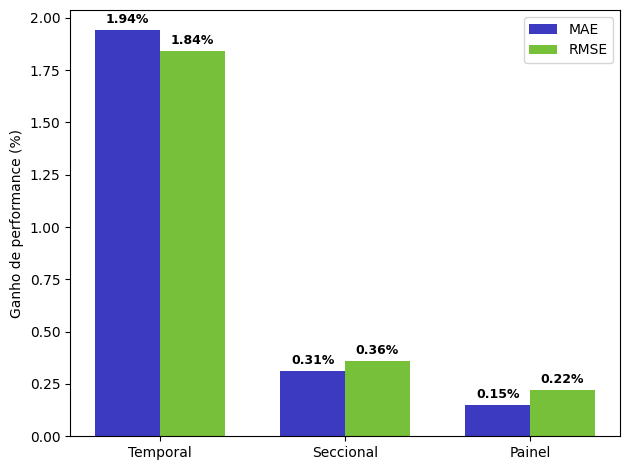

In [63]:
x = np.arange(len(erros_pred.index))

# Largura das barras
largura = 0.35
# Plot das barras lado a lado
barras_mae = plt.bar(x - largura/2, erros_pred['MAE GAIN'].abs(), width=largura,
                     label='MAE', color='#0E0BB3CE')
barras_rmse = plt.bar(x + largura/2, erros_pred['RMSE GAIN'].abs(), width=largura,
                      label='RMSE', color="#57B30BCE")

# Ajusta ticks e rótulos
plt.xticks(x, erros_pred.index)
plt.ylabel("Ganho de performance (%)")
plt.legend()

# Adiciona rótulos de dados
for barra in barras_mae:
    altura = barra.get_height()
    plt.annotate(f'{altura:.2f}%',
                 xy=(barra.get_x() + barra.get_width() / 2, altura),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

for barra in barras_rmse:
    altura = barra.get_height()
    plt.annotate(f'{altura:.2f}%',
                 xy=(barra.get_x() + barra.get_width() / 2, altura),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

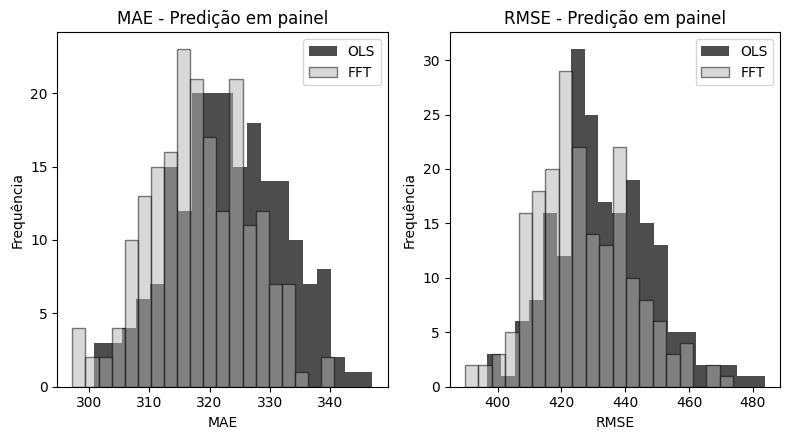

In [64]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4.5))
ax = ax.flatten()

color_ols = "0.3"
color_fft = "0.7"
ax[0].hist(for_panel['MAE OLS'], label='OLS', color=color_ols, bins=20)
ax[0].hist(for_panel['MAE FFT'], label='FFT', edgecolor='0', color=color_fft, alpha=0.5, bins=20)
ax[0].set_title("MAE - Predição em painel")
ax[0].set_xlabel('MAE')
ax[0].set_ylabel('Frequência')
ax[0].legend()

ax[1].hist(for_panel['RMSE OLS'], label='OLS', color=color_ols, bins=20)
ax[1].hist(for_panel['RMSE FFT'], label='FFT', edgecolor='0', color=color_fft, alpha=0.5, bins=20)
ax[1].set_title("RMSE - Predição em painel")
ax[1].set_xlabel('RMSE')
ax[1].set_ylabel('Frequência')
ax[1].legend()

plt.tight_layout()
plt.show()

In [65]:
for_yearly = []

cont_rmse, cont_mae = 0, 0
e_mae_ols, e_mae_fft, e_rmse_ols, e_rmse_fft = 0,0,0,0
for y in range(2007, 2025):
    df_train = df_model[df_model['YEAR'] < y]  # treina sem o ano y
    model_fft_test = smf.ols(formula=formula, data=df_train).fit(cov_type="HC3")  # HC3 = erros robustos
    model_lin_test = smf.ols(formula=formula_lin, data=df_train).fit(cov_type="HC3")

    df_test = df_model[df_model['YEAR'] == y]  # testa no ano y
    preds_fft = model_fft_test.predict(df_test)
    preds_lin = model_lin_test.predict(df_test)

    fft_mae = mae(df_test['PROD_SOJA'], preds_fft).round(2)
    fft_rmse = rmse(df_test['PROD_SOJA'], preds_fft).round(2)
    ols_mae = mae(df_test['PROD_SOJA'], preds_lin).round(2)
    ols_rmse = rmse(df_test['PROD_SOJA'], preds_lin).round(2)

    e_mae_ols += ols_mae
    e_mae_fft += fft_mae
    e_rmse_ols += ols_rmse
    e_rmse_fft += fft_rmse
    if fft_rmse < ols_rmse:
        fft_rmse = '\\textbf{' + str(fft_rmse) + '}'
        ols_rmse = '\\textbf{' + str(ols_rmse) + '}'
        cont_rmse += 1
    if fft_mae < ols_mae:
        fft_mae = '\\textbf{' + str(fft_mae) + '}'
        ols_mae = '\\textbf{' + str(ols_mae) + '}'
        cont_mae += 1

    fft_mae, fft_rmse, ols_mae, ols_rmse = str(fft_mae), str(fft_rmse), str(ols_mae), str(ols_rmse)
    for_yearly.append([y, ols_mae, fft_mae, ols_rmse, fft_rmse])
    

for_yearly = pd.DataFrame(for_yearly, columns=['YEAR', 'MAE OLS', 'MAE FFT', 'RMSE OLS', 'RMSE FFT'])
multi_cols = pd.MultiIndex.from_tuples([
    ('', "Ano"), ('MAE', 'OLS'), ('MAE', 'FFT'),
    ('RMSE', 'OLS'), ('RMSE', 'FFT')
])

for_yearly.columns = multi_cols
# for_yearly
print(for_yearly.to_latex(index=False))

\begin{tabular}{rllll}
\toprule
 & \multicolumn{2}{r}{MAE} & \multicolumn{2}{r}{RMSE} \\
Ano & OLS & FFT & OLS & FFT \\
\midrule
2007 & \textbf{2209.59} & \textbf{1173.85} & \textbf{2259.38} & \textbf{1282.1} \\
2008 & \textbf{315.13} & \textbf{306.79} & \textbf{405.45} & \textbf{398.62} \\
2009 & \textbf{375.7} & \textbf{374.85} & \textbf{525.01} & \textbf{522.17} \\
2010 & 292.82 & 303.89 & 368.89 & 386.86 \\
2011 & \textbf{317.19} & \textbf{313.31} & \textbf{417.52} & \textbf{413.17} \\
2012 & 373.91 & 375.66 & 495.01 & 495.09 \\
2013 & 279.87 & 280.65 & 376.41 & 380.74 \\
2014 & 343.73 & 347.19 & 469.01 & 470.39 \\
2015 & 294.78 & 297.94 & 399.47 & 400.49 \\
2016 & 366.48 & 370.25 & 492.71 & 497.26 \\
2017 & \textbf{406.55} & \textbf{396.12} & \textbf{492.83} & \textbf{483.18} \\
2018 & 307.86 & 308.37 & \textbf{404.27} & \textbf{403.76} \\
2019 & \textbf{357.35} & \textbf{346.58} & \textbf{469.91} & \textbf{457.33} \\
2020 & \textbf{388.21} & \textbf{386.79} & \textbf{521.53} & \t

In [66]:
print(cont_mae/18, cont_rmse/18)
print(e_mae_ols/18, e_mae_fft/18, e_rmse_ols/18, e_rmse_fft/18)

0.5 0.5555555555555556
458.4655555555556 398.7094444444444 569.6600000000002 512.8344444444444


In [67]:
df_test = full_df[full_df['YEAR'] == 2025]
pred_fft = pd.DataFrame(model.predict(df_test), columns=['FFT'])
pred_lin = pd.DataFrame(model_lin.predict(df_test), columns=['LIN'])

df_2025 = df_test[['SIGLA_UF']].merge(
    pred_fft, how='left', left_index=True, right_index=True).merge(
        pred_lin, how='left', left_index=True, right_index=True)

df_2025 = df_2025.groupby('SIGLA_UF')[['FFT', 'LIN']].mean().reset_index()
prod_2025 = pd.read_excel(r"Bases/soja_estimativa_2025.xlsx")
prod_2025['PROD_EST'] = prod_2025['PROD_EST'].replace("-", np.nan, regex=True).astype(float)

df_2025 = df_2025.merge(prod_2025, how='left', on='SIGLA_UF').dropna()

fft_mae = mae(df_2025['PROD_EST'], df_2025['FFT']).round(2)
fft_rmse = rmse(df_2025['PROD_EST'], df_2025['FFT']).round(2)
ols_mae = mae(df_2025['PROD_EST'], df_2025['LIN']).round(2)
ols_rmse = rmse(df_2025['PROD_EST'], df_2025['LIN']).round(2)

if fft_rmse < ols_rmse:
    fft_rmse = '\\textbf{' + str(fft_rmse) + '}'
    ols_rmse = '\\textbf{' + str(ols_rmse) + '}'
if fft_mae < ols_mae:
    fft_mae = '\\textbf{' + str(fft_mae) + '}'
    ols_mae = '\\textbf{' + str(ols_mae) + '}'

fft_mae, fft_rmse, ols_mae, ols_rmse = str(fft_mae), str(fft_rmse), str(ols_mae), str(ols_rmse)

print(ols_mae, fft_mae, ols_rmse, fft_rmse, sep=' & ')

\textbf{288.31} & \textbf{265.74} & \textbf{423.12} & \textbf{399.55}


C:\Users\gustavo.ducatti\AppData\Local\Temp\1\ipykernel_25644\874150888.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  prod_2025['PROD_EST'] = prod_2025['PROD_EST'].replace("-", np.nan, regex=True).astype(float)


In [68]:
df_2025['Erro FFT'] = df_2025['PROD_EST'] - df_2025['FFT']
df_2025['Erro LIN'] = df_2025['PROD_EST'] - df_2025['LIN']

df_2025 = df_2025.round(2).astype(str)
mask = df_2025['Erro FFT'] < df_2025['Erro LIN']

# Para todas as colunas (exceto as de erro, se quiser manter os números)
for col in df_2025.columns:
    df_2025.loc[mask, col] = '\\textbf{' + df_2025.loc[mask, col].astype(str) + '}'

multi_cols = pd.MultiIndex.from_tuples([
    ('', "UF"),
    ('PROD ESTIMADA', 'FFT'), ('PROD ESTIMADA', 'OLS'), ('PROD ESTIMADA', 'IBGE'),
    ('ERRO', 'FFT'), ('ERRO', 'OLS')
])

df_2025.columns = multi_cols



print(df_2025.to_latex(index=False))

\begin{tabular}{llllll}
\toprule
 & \multicolumn{3}{r}{PROD ESTIMADA} & \multicolumn{2}{r}{ERRO} \\
UF & FFT & OLS & IBGE & FFT & OLS \\
\midrule
BA & 3810.74 & 3837.81 & 4015.0 & 204.26 & 177.19 \\
DF & 3875.21 & 3859.89 & 3780.0 & -95.21 & -79.89 \\
GO & 3701.39 & 3707.46 & 3974.0 & 272.61 & 266.54 \\
\textbf{MA} & \textbf{3397.04} & \textbf{3403.7} & \textbf{3209.0} & \textbf{-188.04} & \textbf{-194.7} \\
MG & 3671.0 & 3671.89 & 3860.0 & 189.0 & 188.11 \\
MS & 3456.2 & 3436.13 & 3077.0 & -379.2 & -359.13 \\
\textbf{MT} & \textbf{3796.97} & \textbf{3776.97} & \textbf{3923.0} & \textbf{126.03} & \textbf{146.03} \\
PA & 3524.33 & 3495.61 & 3341.0 & -183.33 & -154.61 \\
\textbf{PI} & \textbf{3616.87} & \textbf{3636.49} & \textbf{3361.0} & \textbf{-255.87} & \textbf{-275.49} \\
\textbf{PR} & \textbf{3637.95} & \textbf{3630.8} & \textbf{3656.0} & \textbf{18.05} & \textbf{25.2} \\
\textbf{RO} & \textbf{3780.22} & \textbf{3709.88} & \textbf{3754.0} & \textbf{-26.22} & \textbf{44.12} \\
\tex

In [71]:
df_2025

PROD ESTIMADA                                     \
             UF               FFT               OLS             IBGE   
0            BA           3810.74           3837.81           4015.0   
1            DF           3875.21           3859.89           3780.0   
2            GO           3701.39           3707.46           3974.0   
3   \textbf{MA}  \textbf{3397.04}   \textbf{3403.7}  \textbf{3209.0}   
4            MG            3671.0           3671.89           3860.0   
5            MS            3456.2           3436.13           3077.0   
6   \textbf{MT}  \textbf{3796.97}  \textbf{3776.97}  \textbf{3923.0}   
7            PA           3524.33           3495.61           3341.0   
8   \textbf{PI}  \textbf{3616.87}  \textbf{3636.49}  \textbf{3361.0}   
9   \textbf{PR}  \textbf{3637.95}   \textbf{3630.8}  \textbf{3656.0}   
10  \textbf{RO}  \textbf{3780.22}  \textbf{3709.88}  \textbf{3754.0}   
11  \textbf{RR}  \textbf{3383.08}  \textbf{3114.36}  \textbf{3577.0}   
12  \textbf{RS}  \textbf{3364.89}  \textbf{3402.79}  \textbf{2010.0}   
13  \textbf{SC}  \textbf{3499.37}  \textbf{3419.65}  \textbf{3810.0}   
14           SP           3553.65           3566.51           3893.0   
15  \textbf{TO}  \textbf{3636.26}  \textbf{3650.66}  \textbf{3521.0}   

                 ERRO                     
                  FFT                OLS  
0              204.26             177.19  
1              -95.21             -79.89  
2              272.61             266.54  
3    \textbf{-188.04}    \textbf{-194.7}  
4               189.0             188.11  
5              -379.2            -359.13  
6     \textbf{126.03}    \textbf{146.03}  
7             -183.33            -154.61  
8    \textbf{-255.87}   \textbf{-275.49}  
9      \textbf{18.05}      \textbf{25.2}  
10    \textbf{-26.22}     \textbf{44.12}  
11    \textbf{193.92}    \textbf{462.64}  
12  \textbf{-1354.89}  \textbf{-1392.79}  
13    \textbf{310.63}    \textbf{390.35}  
14             339.35             326.49  
15   \textbf{-115.26}   \textbf{-129.66}